# Step 4 — P300 ERP Verification: All Subjects

This notebook extends the single-subject ERP analysis to **all available subjects** in the preprocessed dataset.

For each subject it:
- separates Target and NonTarget epochs,
- computes Target and NonTarget ERPs,
- analyzes Pz (or the closest available parietal channel),
- quantifies the 300–500 ms response,
- records peak latency/amplitude and mean amplitude,
- performs a descriptive sanity check,
- preserves per-subject results,
- computes grand-average Target and NonTarget ERPs,
- creates the required grand-average plot.

**Important:** this notebook reports the observed results. It does not modify preprocessing or force subjects to match an expected pattern.


## 1. Imports and configuration


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

mne.set_log_level("WARNING")

# Find the project root from the current directory or one of its parents.
_current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (candidate for candidate in (_current, *_current.parents) if (candidate / "Pipfile").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root (expected Pipfile).")

DATASET_NAME = "BNCI2014-008"
PREPROCESSED_DIR = PROJECT_ROOT / "data" / "preprocessed"
RESULTS_DIR = PROJECT_ROOT / "results" / "ERP" / DATASET_NAME
FIGURES_DIR = PROJECT_ROOT / "figures" / "ERP" / DATASET_NAME

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# BNCI2014-008 ERP outputs are kept at the project-root results/ and figures/ folders.
SUBJECT_IDS = range(1, 9)
PRIMARY_CHANNEL = "Pz"
PARIETAL_CHANNELS = ["Pz", "P3", "P4", "PO7", "PO8", "Cz"]
P300_WINDOW = (0.300, 0.500)
PLOT_WINDOW = (-0.200, 0.800)

print(f"Preprocessed data: {PREPROCESSED_DIR.resolve()}")
print(f"Results directory:  {RESULTS_DIR.resolve()}")
print(f"Figures directory:  {FIGURES_DIR.resolve()}")
print(f"Subjects: {list(SUBJECT_IDS)}")


Preprocessed data: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/data/preprocessed
Results directory:  /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/results/ERP/BNCI2014-008
Figures directory:  /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/ERP/BNCI2014-008
Subjects: [1, 2, 3, 4, 5, 6, 7, 8]


## 2. Helper functions

The functions below keep the calculations identical across subjects so the per-subject results and grand average are comparable.


In [2]:
def select_erp_channel(evoked, preferred=PRIMARY_CHANNEL):
    """Return Pz when available, otherwise the first available parietal channel."""
    if preferred in evoked.ch_names:
        return preferred

    for ch in PARIETAL_CHANNELS:
        if ch in evoked.ch_names:
            return ch

    raise ValueError("No preferred or parietal ERP Analysis channel is available.")


def mean_amplitude_uv(evoked, channel, window=P300_WINDOW):
    """Mean ERP Analysis amplitude in microvolts within the requested time window."""
    ch_idx = evoked.ch_names.index(channel)
    mask = (evoked.times >= window[0]) & (evoked.times <= window[1])

    if not np.any(mask):
        raise ValueError(f"No samples found in window {window}.")

    amplitude_uv = evoked.data[ch_idx, mask] * 1e6
    return float(np.mean(amplitude_uv))


def positive_peak_uv(evoked, channel, window=P300_WINDOW):
    """Maximum positive ERP Analysis amplitude and its latency within the requested window."""
    ch_idx = evoked.ch_names.index(channel)
    mask = (evoked.times >= window[0]) & (evoked.times <= window[1])

    if not np.any(mask):
        raise ValueError(f"No samples found in window {window}.")

    values_uv = evoked.data[ch_idx, mask] * 1e6
    times_ms = evoked.times[mask] * 1000
    peak_idx = int(np.argmax(values_uv))

    return float(times_ms[peak_idx]), float(values_uv[peak_idx])


def plot_erp(ax, target_evoked, nontarget_evoked, channel, title):
    """Plot Target and NonTarget ERPs on one axis."""
    ch_idx_t = target_evoked.ch_names.index(channel)
    ch_idx_n = nontarget_evoked.ch_names.index(channel)

    times_ms = target_evoked.times * 1000
    target_uv = target_evoked.data[ch_idx_t] * 1e6
    nontarget_uv = nontarget_evoked.data[ch_idx_n] * 1e6

    ax.plot(times_ms, target_uv, label="Target", linewidth=2)
    ax.plot(times_ms, nontarget_uv, label="NonTarget", linewidth=2)
    ax.axvline(0, linestyle="--", linewidth=1, label="Stimulus onset (0 ms)")
    ax.axvspan(300, 500, alpha=0.2, label="P300 window (300–500 ms)")

    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Amplitude (µV)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()


## 3. Locate available subject files


In [3]:
subject_files = {}

for subject_id in SUBJECT_IDS:
    path = PREPROCESSED_DIR / f"subject_{subject_id}_clean-epo.fif"
    if path.exists():
        subject_files[subject_id] = path
    else:
        print(f"[WARNING] Missing Subject {subject_id:02d}: {path}")

print(f"Found {len(subject_files)} subject files.")
print("Subjects found:", [f"{s:02d}" for s in subject_files])

if not subject_files:
    raise FileNotFoundError("No preprocessed subject epoch files were found.")


Found 8 subject files.
Subjects found: ['01', '02', '03', '04', '05', '06', '07', '08']


## 4. Load and inspect all subjects

This section checks the event labels, epoch counts, channels, sampling frequency, time range, and units before ERP averaging.


In [4]:
epochs_by_subject = {}
dataset_checks = []

for subject_id, path in subject_files.items():
    epochs = mne.read_epochs(path, preload=True, verbose=False)
    epochs_by_subject[subject_id] = epochs

    target_count = len(epochs["Target"])
    nontarget_count = len(epochs["NonTarget"])

    dataset_checks.append({
        "Subject": f"{subject_id:02d}",
        "Target epochs": target_count,
        "NonTarget epochs": nontarget_count,
        "Total epochs": len(epochs),
        "Sampling frequency (Hz)": epochs.info["sfreq"],
        "Start (s)": epochs.tmin,
        "End (s)": epochs.tmax,
        "Pz available": "Pz" in epochs.ch_names,
        "EEG channels": len(mne.pick_types(epochs.info, eeg=True, exclude=[])),
    })

dataset_checks_df = pd.DataFrame(dataset_checks)
display(dataset_checks_df)

dataset_checks_df.to_csv(
    RESULTS_DIR / f"{DATASET_NAME}_all_subject_dataset_checks.csv",
    index=False
)


,Subject,Target epochs,NonTarget epochs,Total epochs,Sampling frequency (Hz),Start (s),End (s),Pz available,EEG channels
0,01,697,3463,4160,256.0,-0.199219,0.800781,True,8
1,02,677,3392,4069,256.0,-0.199219,0.800781,True,8
2,03,684,3416,4100,256.0,-0.199219,0.800781,True,8
3,04,698,3486,4184,256.0,-0.199219,0.800781,True,8
4,05,699,3489,4188,256.0,-0.199219,0.800781,True,8
5,06,695,3477,4172,256.0,-0.199219,0.800781,True,8
6,07,506,2914,3420,256.0,-0.199219,0.800781,True,8
7,08,700,3496,4196,256.0,-0.199219,0.800781,True,8


## 5. Target / NonTarget ERP for every subject

Each subject is averaged separately first. This preserves the per-participant results before the grand average is calculated.


In [5]:
target_evokeds = {}
nontarget_evokeds = {}
subject_rows = []

for subject_id, epochs in epochs_by_subject.items():
    target_epochs = epochs["Target"]
    nontarget_epochs = epochs["NonTarget"]

    target_evoked = target_epochs.average()
    nontarget_evoked = nontarget_epochs.average()

    target_evoked.comment = f"Subject {subject_id:02d} Target"
    nontarget_evoked.comment = f"Subject {subject_id:02d} NonTarget"

    target_evokeds[subject_id] = target_evoked
    nontarget_evokeds[subject_id] = nontarget_evoked

    # Preserve the condition averages for every subject in MNE's native format.
    EPOKED_DIR = RESULTS_DIR / "evokeds"
    EPOKED_DIR.mkdir(parents=True, exist_ok=True)
    mne.write_evokeds(
        EPOKED_DIR / f"{DATASET_NAME}_subject_{subject_id:02d}_target-ave.fif",
        target_evoked,
        overwrite=True,
        verbose=False,
    )
    mne.write_evokeds(
        EPOKED_DIR / f"{DATASET_NAME}_subject_{subject_id:02d}_nontarget-ave.fif",
        nontarget_evoked,
        overwrite=True,
        verbose=False,
    )

    channel = select_erp_channel(target_evoked)

    target_mean = mean_amplitude_uv(target_evoked, channel)
    nontarget_mean = mean_amplitude_uv(nontarget_evoked, channel)

    target_peak_latency, target_peak_amp = positive_peak_uv(target_evoked, channel)
    nontarget_peak_latency, nontarget_peak_amp = positive_peak_uv(nontarget_evoked, channel)

    difference = target_mean - nontarget_mean

    # This is a descriptive diagnostic rule, not a formal project acceptance criterion.
    sanity = (
        "EXPECTED_PATTERN"
        if target_mean > nontarget_mean and target_peak_amp > nontarget_peak_amp
        else "UNEXPECTED_PATTERN"
    )

    subject_rows.append({
        "Subject": f"{subject_id:02d}",
        "Target epoch count": len(target_epochs),
        "NonTarget epoch count": len(nontarget_epochs),
        "ERP Analysis channel": channel,
        "Target mean 300–500 ms (µV)": target_mean,
        "NonTarget mean 300–500 ms (µV)": nontarget_mean,
        "Target − NonTarget (µV)": difference,
        "Target peak latency (ms)": target_peak_latency,
        "Target peak amplitude (µV)": target_peak_amp,
        "NonTarget peak latency (ms)": nontarget_peak_latency,
        "NonTarget peak amplitude (µV)": nontarget_peak_amp,
        "Sanity check": sanity,
    })

per_subject_df = pd.DataFrame(subject_rows).sort_values("Subject").reset_index(drop=True)

display(per_subject_df.round(3))

per_subject_df.to_csv(
    RESULTS_DIR / f"{DATASET_NAME}_per_subject_erp_results.csv",
    index=False
)


,Subject,Target epoch count,NonTarget epoch count,ERP Analysis channel,Target mean 300–500 ms (µV),NonTarget mean 300–500 ms (µV),Target − NonTarget (µV),Target peak latency (ms),Target peak amplitude (µV),NonTarget peak latency (ms),NonTarget peak amplitude (µV),Sanity check
0,01,697,3463,Pz,0.146,-0.025,0.171,343.750,1.379,343.750,0.688,EXPECTED_PATTERN
1,02,677,3392,Pz,-0.382,0.048,-0.430,500.000,1.049,500.000,0.337,UNEXPECTED_PATTERN
2,03,684,3416,Pz,-0.002,-0.008,0.006,300.781,1.496,371.094,0.948,EXPECTED_PATTERN
3,04,698,3486,Pz,0.546,-0.090,0.636,378.906,1.941,371.094,0.797,EXPECTED_PATTERN
4,05,699,3489,Pz,-0.619,0.116,-0.735,476.562,0.350,375.000,0.841,UNEXPECTED_PATTERN
5,06,695,3477,Pz,1.068,-0.197,1.265,382.812,2.484,359.375,0.698,EXPECTED_PATTERN
6,07,506,2914,Pz,-0.299,0.121,-0.419,500.000,2.077,414.062,0.654,UNEXPECTED_PATTERN
7,08,700,3496,Pz,-0.802,0.160,-0.962,500.000,0.736,378.906,1.488,UNEXPECTED_PATTERN


## 6. Per-subject ERP plots

A separate plot is saved for every subject so the individual responses can be inspected rather than relying only on the grand average.


In [6]:
PER_SUBJECT_FIG_DIR = FIGURES_DIR / "per_subject"
PER_SUBJECT_FIG_DIR.mkdir(parents=True, exist_ok=True)

for subject_id in target_evokeds:
    target_evoked = target_evokeds[subject_id]
    nontarget_evoked = nontarget_evokeds[subject_id]
    channel = select_erp_channel(target_evoked)

    fig, ax = plt.subplots(figsize=(9, 5))
    plot_erp(
        ax,
        target_evoked,
        nontarget_evoked,
        channel,
        f"Subject {subject_id:02d} — Target vs NonTarget ERP Analysis at {channel}"
    )
    fig.tight_layout()
    fig.savefig(
        PER_SUBJECT_FIG_DIR / f"{DATASET_NAME}_subject_{subject_id:02d}_target_vs_nontarget.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.close(fig)

print(f"Saved per-subject ERP Analysis plots to: {PER_SUBJECT_FIG_DIR.resolve()}")


Saved per-subject ERP Analysis plots to: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/ERP/BNCI2014-008/per_subject


## 7. Grand-average Target and NonTarget ERPs

The grand average gives every subject equal weight: each subject contributes one subject-level ERP to the grand average.


In [7]:
target_evoked_list = [target_evokeds[s] for s in sorted(target_evokeds)]
nontarget_evoked_list = [nontarget_evokeds[s] for s in sorted(nontarget_evokeds)]

grand_target_evoked = mne.grand_average(
    target_evoked_list,
    interpolate_bads=False,
    drop_bads=False,
)

grand_nontarget_evoked = mne.grand_average(
    nontarget_evoked_list,
    interpolate_bads=False,
    drop_bads=False,
)

grand_channel = select_erp_channel(grand_target_evoked)

print(f"Subjects included in grand average: {len(target_evoked_list)}")
print(f"Grand-average analysis channel: {grand_channel}")


Subjects included in grand average: 8
Grand-average analysis channel: Pz


## 8. Grand-average ERP plot


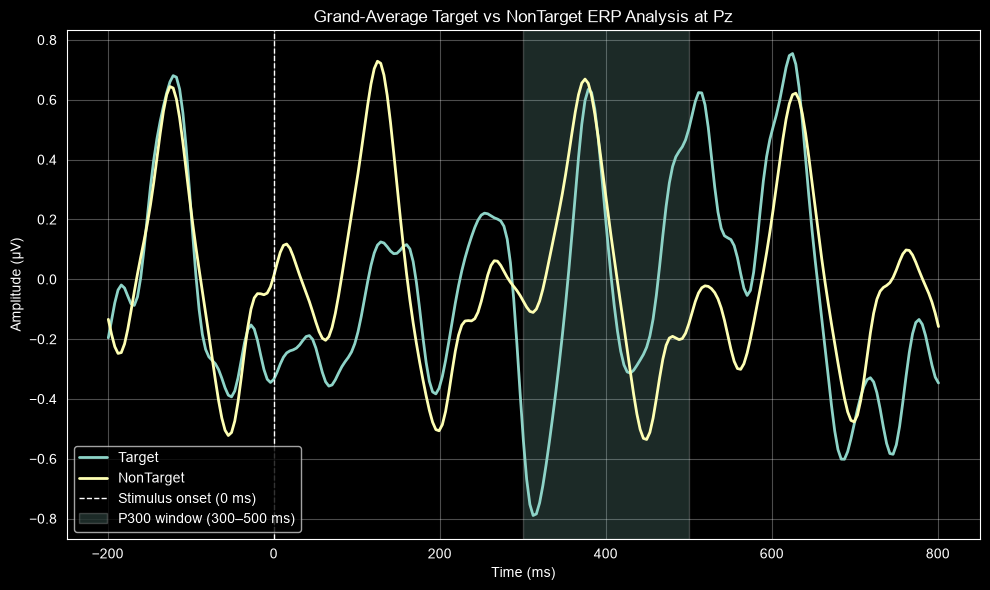

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/ERP/BNCI2014-008/BNCI2014-008_grand_average_target_vs_nontarget.png


In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

plot_erp(
    ax,
    grand_target_evoked,
    grand_nontarget_evoked,
    grand_channel,
    f"Grand-Average Target vs NonTarget ERP Analysis at {grand_channel}"
)

fig.tight_layout()

grand_plot_path = FIGURES_DIR / f"{DATASET_NAME}_grand_average_target_vs_nontarget.png"
fig.savefig(grand_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved: {grand_plot_path.resolve()}")


## 9. Grand-average P300 measurements


In [9]:
grand_target_mean = mean_amplitude_uv(
    grand_target_evoked,
    grand_channel,
    P300_WINDOW
)

grand_nontarget_mean = mean_amplitude_uv(
    grand_nontarget_evoked,
    grand_channel,
    P300_WINDOW
)

grand_target_peak_latency, grand_target_peak_amp = positive_peak_uv(
    grand_target_evoked,
    grand_channel,
    P300_WINDOW
)

grand_nontarget_peak_latency, grand_nontarget_peak_amp = positive_peak_uv(
    grand_nontarget_evoked,
    grand_channel,
    P300_WINDOW
)

grand_difference = grand_target_mean - grand_nontarget_mean

grand_results = pd.DataFrame([{
    "Analysis": "Grand average",
    "Subjects included": len(target_evoked_list),
    "Channel": grand_channel,
    "P300 window": "300–500 ms",
    "Target mean amplitude (µV)": grand_target_mean,
    "NonTarget mean amplitude (µV)": grand_nontarget_mean,
    "Target − NonTarget mean (µV)": grand_difference,
    "Target peak latency (ms)": grand_target_peak_latency,
    "Target peak amplitude (µV)": grand_target_peak_amp,
    "NonTarget peak latency (ms)": grand_nontarget_peak_latency,
    "NonTarget peak amplitude (µV)": grand_nontarget_peak_amp,
}])

display(grand_results.round(3))

grand_results.to_csv(
    RESULTS_DIR / f"{DATASET_NAME}_grand_average_erp_results.csv",
    index=False
)


,Analysis,Subjects included,Channel,P300 window,Target mean amplitude (µV),NonTarget mean amplitude (µV),Target − NonTarget mean (µV),Target peak latency (ms),Target peak amplitude (µV),NonTarget peak latency (ms),NonTarget peak amplitude (µV)
0,Grand average,8,Pz,300–500 ms,-0.043,0.016,-0.059,378.906,0.635,375.0,0.669


## 10. Target − NonTarget grand difference wave

The difference wave makes the direction of the Target-versus-NonTarget effect explicit.


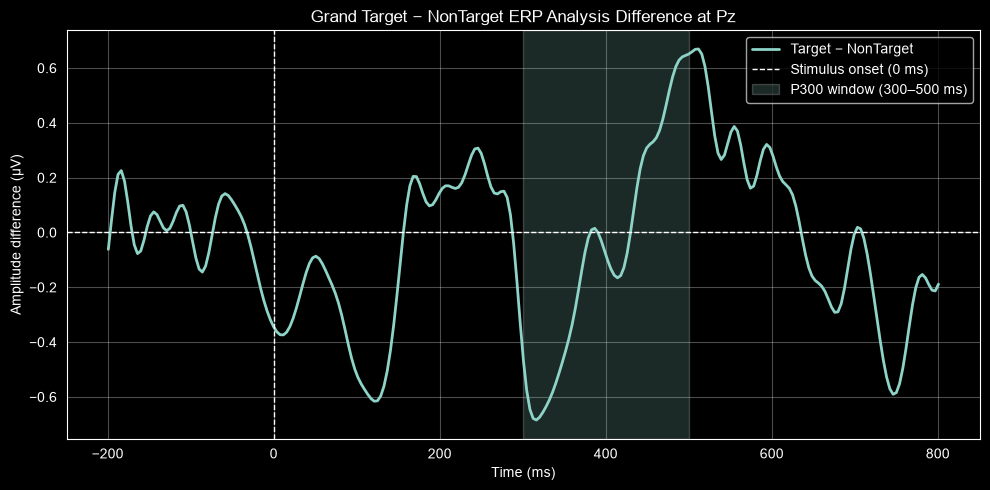

Saved: /Users/ziadelsisi/Hello World/Projects/Graduation Project /eeg-p300-recognition-assessment/figures/ERP/BNCI2014-008/BNCI2014-008_grand_average_target_minus_nontarget.png


In [10]:
ch_idx_t = grand_target_evoked.ch_names.index(grand_channel)
ch_idx_n = grand_nontarget_evoked.ch_names.index(grand_channel)

times_ms = grand_target_evoked.times * 1000
difference_uv = (
    grand_target_evoked.data[ch_idx_t] * 1e6
    - grand_nontarget_evoked.data[ch_idx_n] * 1e6
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times_ms, difference_uv, linewidth=2, label="Target − NonTarget")
ax.axhline(0, linestyle="--", linewidth=1)
ax.axvline(0, linestyle="--", linewidth=1, label="Stimulus onset (0 ms)")
ax.axvspan(300, 500, alpha=0.2, label="P300 window (300–500 ms)")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Amplitude difference (µV)")
ax.set_title(f"Grand Target − NonTarget ERP Analysis Difference at {grand_channel}")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

difference_plot_path = FIGURES_DIR / f"{DATASET_NAME}_grand_average_target_minus_nontarget.png"
fig.savefig(difference_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved: {difference_plot_path.resolve()}")


## 11. Multi-channel 300–500 ms comparison

This checks whether the Target-versus-NonTarget difference is specific to Pz or appears at other available EEG channels as well.


In [11]:
channel_rows = []

for channel in grand_target_evoked.ch_names:
    target_mean = mean_amplitude_uv(grand_target_evoked, channel, P300_WINDOW)
    nontarget_mean = mean_amplitude_uv(grand_nontarget_evoked, channel, P300_WINDOW)

    channel_rows.append({
        "Channel": channel,
        "Target mean 300–500 ms (µV)": target_mean,
        "NonTarget mean 300–500 ms (µV)": nontarget_mean,
        "Target − NonTarget (µV)": target_mean - nontarget_mean,
    })

grand_channel_df = pd.DataFrame(channel_rows)
display(grand_channel_df.round(3))

grand_channel_df.to_csv(
    RESULTS_DIR / f"{DATASET_NAME}_grand_average_channel_comparison.csv",
    index=False
)


,Channel,Target mean 300–500 ms (µV),NonTarget mean 300–500 ms (µV),Target − NonTarget (µV)
0,Fz,0.870,-0.117,0.987
1,Cz,0.542,-0.087,0.629
2,Pz,-0.043,0.016,-0.059
3,Oz,-0.101,0.015,-0.117
4,P3,0.025,0.003,0.022
5,P4,0.111,-0.013,0.124
6,PO7,-0.255,0.052,-0.307
7,PO8,-0.240,0.048,-0.288


## 12. Identify subjects requiring inspection

The `UNEXPECTED_PATTERN` label is a descriptive diagnostic rule used by this notebook. It is **not** a formal project acceptance criterion.


In [12]:
unexpected_df = per_subject_df[
    per_subject_df["Sanity check"] == "UNEXPECTED_PATTERN"
].copy()

print(f"Unexpected-pattern subjects: {len(unexpected_df)}")
display(unexpected_df.round(3))


Unexpected-pattern subjects: 4


,Subject,Target epoch count,NonTarget epoch count,ERP Analysis channel,Target mean 300–500 ms (µV),NonTarget mean 300–500 ms (µV),Target − NonTarget (µV),Target peak latency (ms),Target peak amplitude (µV),NonTarget peak latency (ms),NonTarget peak amplitude (µV),Sanity check
1,02,677,3392,Pz,-0.382,0.048,-0.430,500.000,1.049,500.000,0.337,UNEXPECTED_PATTERN
4,05,699,3489,Pz,-0.619,0.116,-0.735,476.562,0.350,375.000,0.841,UNEXPECTED_PATTERN
6,07,506,2914,Pz,-0.299,0.121,-0.419,500.000,2.077,414.062,0.654,UNEXPECTED_PATTERN
7,08,700,3496,Pz,-0.802,0.160,-0.962,500.000,0.736,378.906,1.488,UNEXPECTED_PATTERN


## 13. Compact Step 4 summary

This final table is the one to use when completing the Step 4 documentation. It reports the aggregate result while retaining the per-subject evidence separately.


In [13]:
expected_count = int((per_subject_df["Sanity check"] == "EXPECTED_PATTERN").sum())
unexpected_count = int((per_subject_df["Sanity check"] == "UNEXPECTED_PATTERN").sum())

step4_summary = pd.DataFrame([{
    "Primary analysis channel": grand_channel,
    "Secondary channels": ", ".join([c for c in grand_target_evoked.ch_names if c != grand_channel]),
    "P300 window": "300–500 ms",
    "Target mean amplitude (grand average, µV)": grand_target_mean,
    "NonTarget mean amplitude (grand average, µV)": grand_nontarget_mean,
    "Target − NonTarget mean (grand average, µV)": grand_difference,
    "Target peak latency (grand average, ms)": grand_target_peak_latency,
    "Target peak amplitude (grand average, µV)": grand_target_peak_amp,
    "Subjects analyzed": len(target_evoked_list),
    "Subjects EXPECTED": expected_count,
    "Subjects UNEXPECTED": unexpected_count,
    "Grand-average plot": str(grand_plot_path),
}])

display(step4_summary.round(3))

step4_summary.to_csv(
    RESULTS_DIR / f"{DATASET_NAME}_step4_all_subjects_summary.csv",
    index=False
)


,Primary analysis channel,Secondary channels,P300 window,"Target mean amplitude (grand average, µV)","NonTarget mean amplitude (grand average, µV)","Target − NonTarget mean (grand average, µV)","Target peak latency (grand average, ms)","Target peak amplitude (grand average, µV)",Subjects analyzed,Subjects EXPECTED,Subjects UNEXPECTED,Grand-average plot
0,Pz,"Fz, Cz, Oz, P3, P4, PO7, PO8",300–500 ms,-0.043,0.016,-0.059,378.906,0.635,8,4,4,/Users/ziadelsisi/Hello World/Projects/Graduat...


## 14. Output files

Main outputs:

- `results/ERP/BNCI2014-008/BNCI2014-008_per_subject_erp_results.csv` — one row per subject.
- `results/ERP/BNCI2014-008/BNCI2014-008_grand_average_erp_results.csv` — aggregate Target/NonTarget ERP measurements.
- `results/ERP/BNCI2014-008/BNCI2014-008_grand_average_channel_comparison.csv` — 300–500 ms comparison across channels.
- `results/ERP/BNCI2014-008/BNCI2014-008_step4_all_subjects_summary.csv` — compact Step 4 summary.
- `figures/ERP/BNCI2014-008/BNCI2014-008_grand_average_target_vs_nontarget.png` — required grand-average ERP plot.
- `figures/ERP/BNCI2014-008/BNCI2014-008_grand_average_target_minus_nontarget.png` — grand difference wave.
- `figures/ERP/BNCI2014-008/per_subject/` — individual subject ERP plots.
- `results/ERP/BNCI2014-008/evokeds/` — Target and NonTarget MNE Evoked files for every subject.

The results are observational: unexpected subject behavior is reported rather than hidden or altered.
